In [1]:
!pip install pandas numpy matplotlib seaborn scikit-learn

In [2]:
# Step 1: Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    roc_curve,
    roc_auc_score
)

In [6]:
# Step 2: Load dataset
diabetes_data = pd.read_csv("C:/Users/prath/Downloads/ML_PRAC/diabetes.csv")

In [7]:
# Step 3: Display first five records
print("First five records:")
print(diabetes_data.head())

First five records:
   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   Pedigree  Age  Outcome  
0     0.627   50        1  
1     0.351   31        0  
2     0.672   32        1  
3     0.167   21        0  
4     2.288   33        1  


In [8]:
# Step 4: Check dataset information
print("\nDataset Information:")
diabetes_data.info()


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Pregnancies    768 non-null    int64  
 1   Glucose        768 non-null    int64  
 2   BloodPressure  768 non-null    int64  
 3   SkinThickness  768 non-null    int64  
 4   Insulin        768 non-null    int64  
 5   BMI            768 non-null    float64
 6   Pedigree       768 non-null    float64
 7   Age            768 non-null    int64  
 8   Outcome        768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [10]:
# Step 5: Statistical analysis
print("\nStatistical Description:")
print(diabetes_data.describe())

print("\nDataset Shape:")
print(diabetes_data.shape)


Statistical Description:
       Pregnancies     Glucose  BloodPressure  SkinThickness     Insulin  \
count   768.000000  768.000000     768.000000     768.000000  768.000000   
mean      3.845052  120.894531      69.105469      20.536458   79.799479   
std       3.369578   31.972618      19.355807      15.952218  115.244002   
min       0.000000    0.000000       0.000000       0.000000    0.000000   
25%       1.000000   99.000000      62.000000       0.000000    0.000000   
50%       3.000000  117.000000      72.000000      23.000000   30.500000   
75%       6.000000  140.250000      80.000000      32.000000  127.250000   
max      17.000000  199.000000     122.000000      99.000000  846.000000   

              BMI    Pedigree         Age     Outcome  
count  768.000000  768.000000  768.000000  768.000000  
mean    31.992578    0.471876   33.240885    0.348958  
std      7.884160    0.331329   11.760232    0.476951  
min      0.000000    0.078000   21.000000    0.000000  
25%     2

In [11]:
# Step 6: Check missing values
print("\nMissing Values:")
print(diabetes_data.isnull().sum())


Missing Values:
Pregnancies      0
Glucose          0
BloodPressure    0
SkinThickness    0
Insulin          0
BMI              0
Pedigree         0
Age              0
Outcome          0
dtype: int64


In [12]:
# Step 7: Replace invalid zero values with NaN
diabetes_data_copy = diabetes_data.copy()

columns = [
    'Glucose',
    'BloodPressure',
    'SkinThickness',
    'Insulin',
    'BMI'
]

diabetes_data_copy[columns] = diabetes_data_copy[columns].replace(0, np.nan)

print("\nInvalid zero values replaced:")
print(diabetes_data_copy.isnull().sum())



Invalid zero values replaced:
Pregnancies        0
Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
Pedigree           0
Age                0
Outcome            0
dtype: int64


In [14]:
# Step 8: Fill missing values

diabetes_data_copy['Glucose'] = diabetes_data_copy['Glucose'].fillna(
    diabetes_data_copy['Glucose'].mean()
)

diabetes_data_copy['BloodPressure'] = diabetes_data_copy['BloodPressure'].fillna(
    diabetes_data_copy['BloodPressure'].mean()
)

diabetes_data_copy['SkinThickness'] = diabetes_data_copy['SkinThickness'].fillna(
    diabetes_data_copy['SkinThickness'].median()
)

diabetes_data_copy['Insulin'] = diabetes_data_copy['Insulin'].fillna(
    diabetes_data_copy['Insulin'].median()
)

diabetes_data_copy['BMI'] = diabetes_data_copy['BMI'].fillna(
    diabetes_data_copy['BMI'].median()
)

print("\nAfter Data Cleaning:")
print(diabetes_data_copy.isnull().sum())


After Data Cleaning:
Pregnancies      0
Glucose          0
BloodPressure    0
SkinThickness    0
Insulin          0
BMI              0
Pedigree         0
Age              0
Outcome          0
dtype: int64


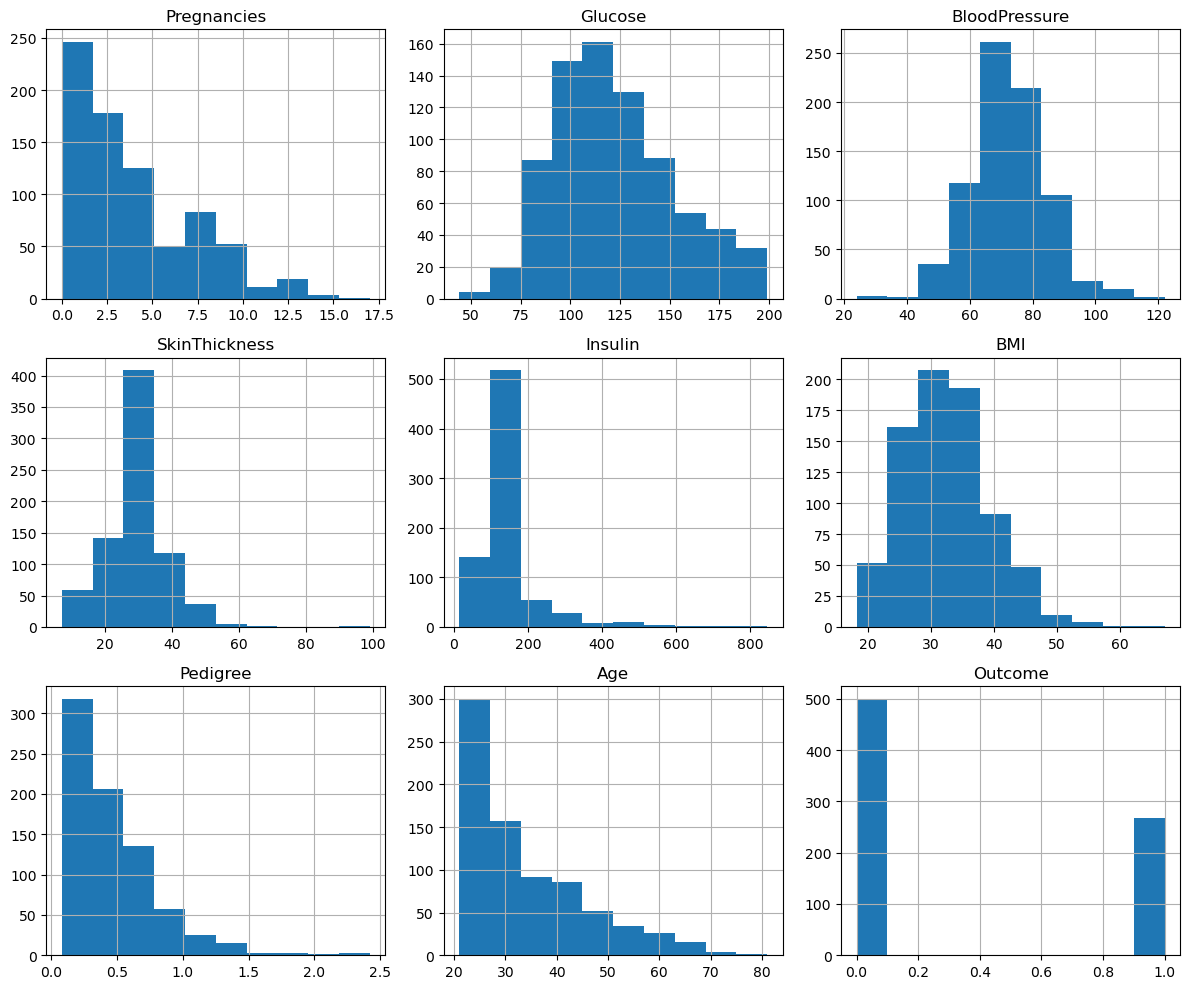

In [15]:
# Step 9: Visualize dataset using histograms
diabetes_data_copy.hist(figsize=(12, 10))
plt.tight_layout()
plt.show()


Outcome Counts:
Outcome
0    500
1    268
Name: count, dtype: int64


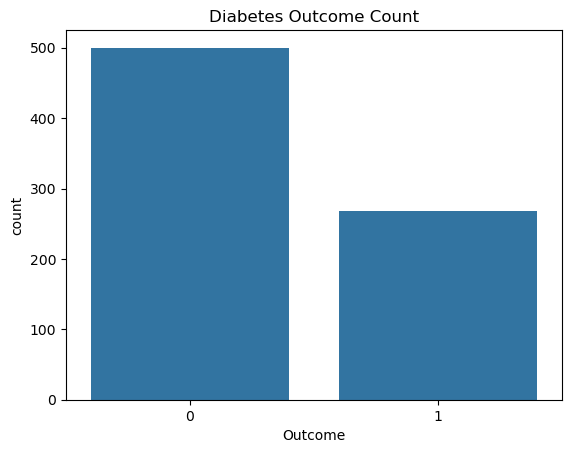

In [16]:
# Step 10: Count of diabetes outcomes
print("\nOutcome Counts:")
print(diabetes_data_copy['Outcome'].value_counts())

sns.countplot(x='Outcome', data=diabetes_data_copy)
plt.title("Diabetes Outcome Count")
plt.show()


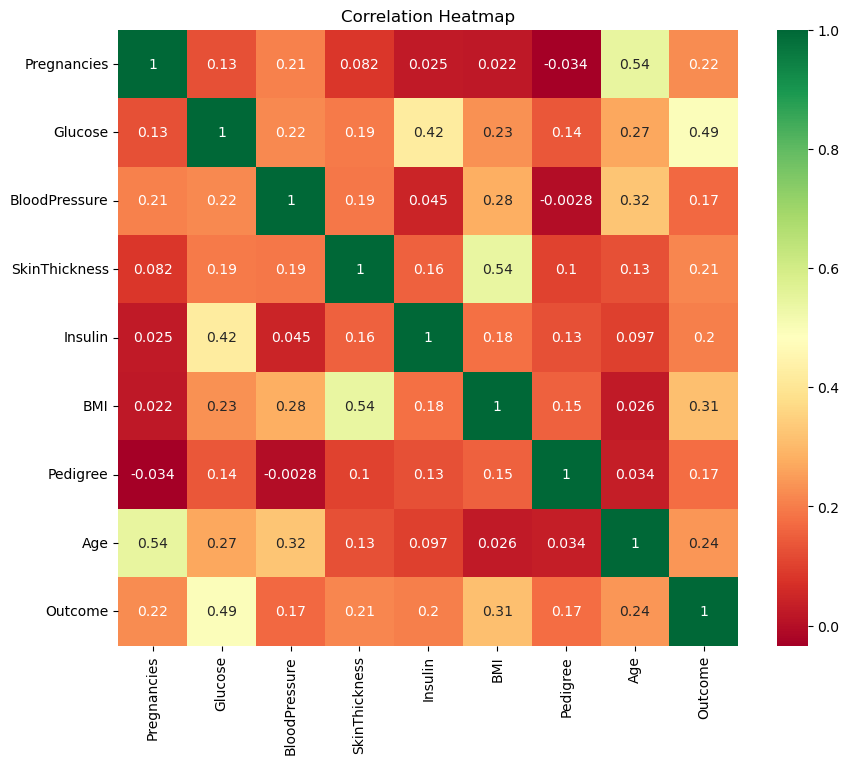

In [17]:
# Step 11: Correlation heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(
    diabetes_data_copy.corr(),
    annot=True,
    cmap='RdYlGn'
)
plt.title("Correlation Heatmap")
plt.show()


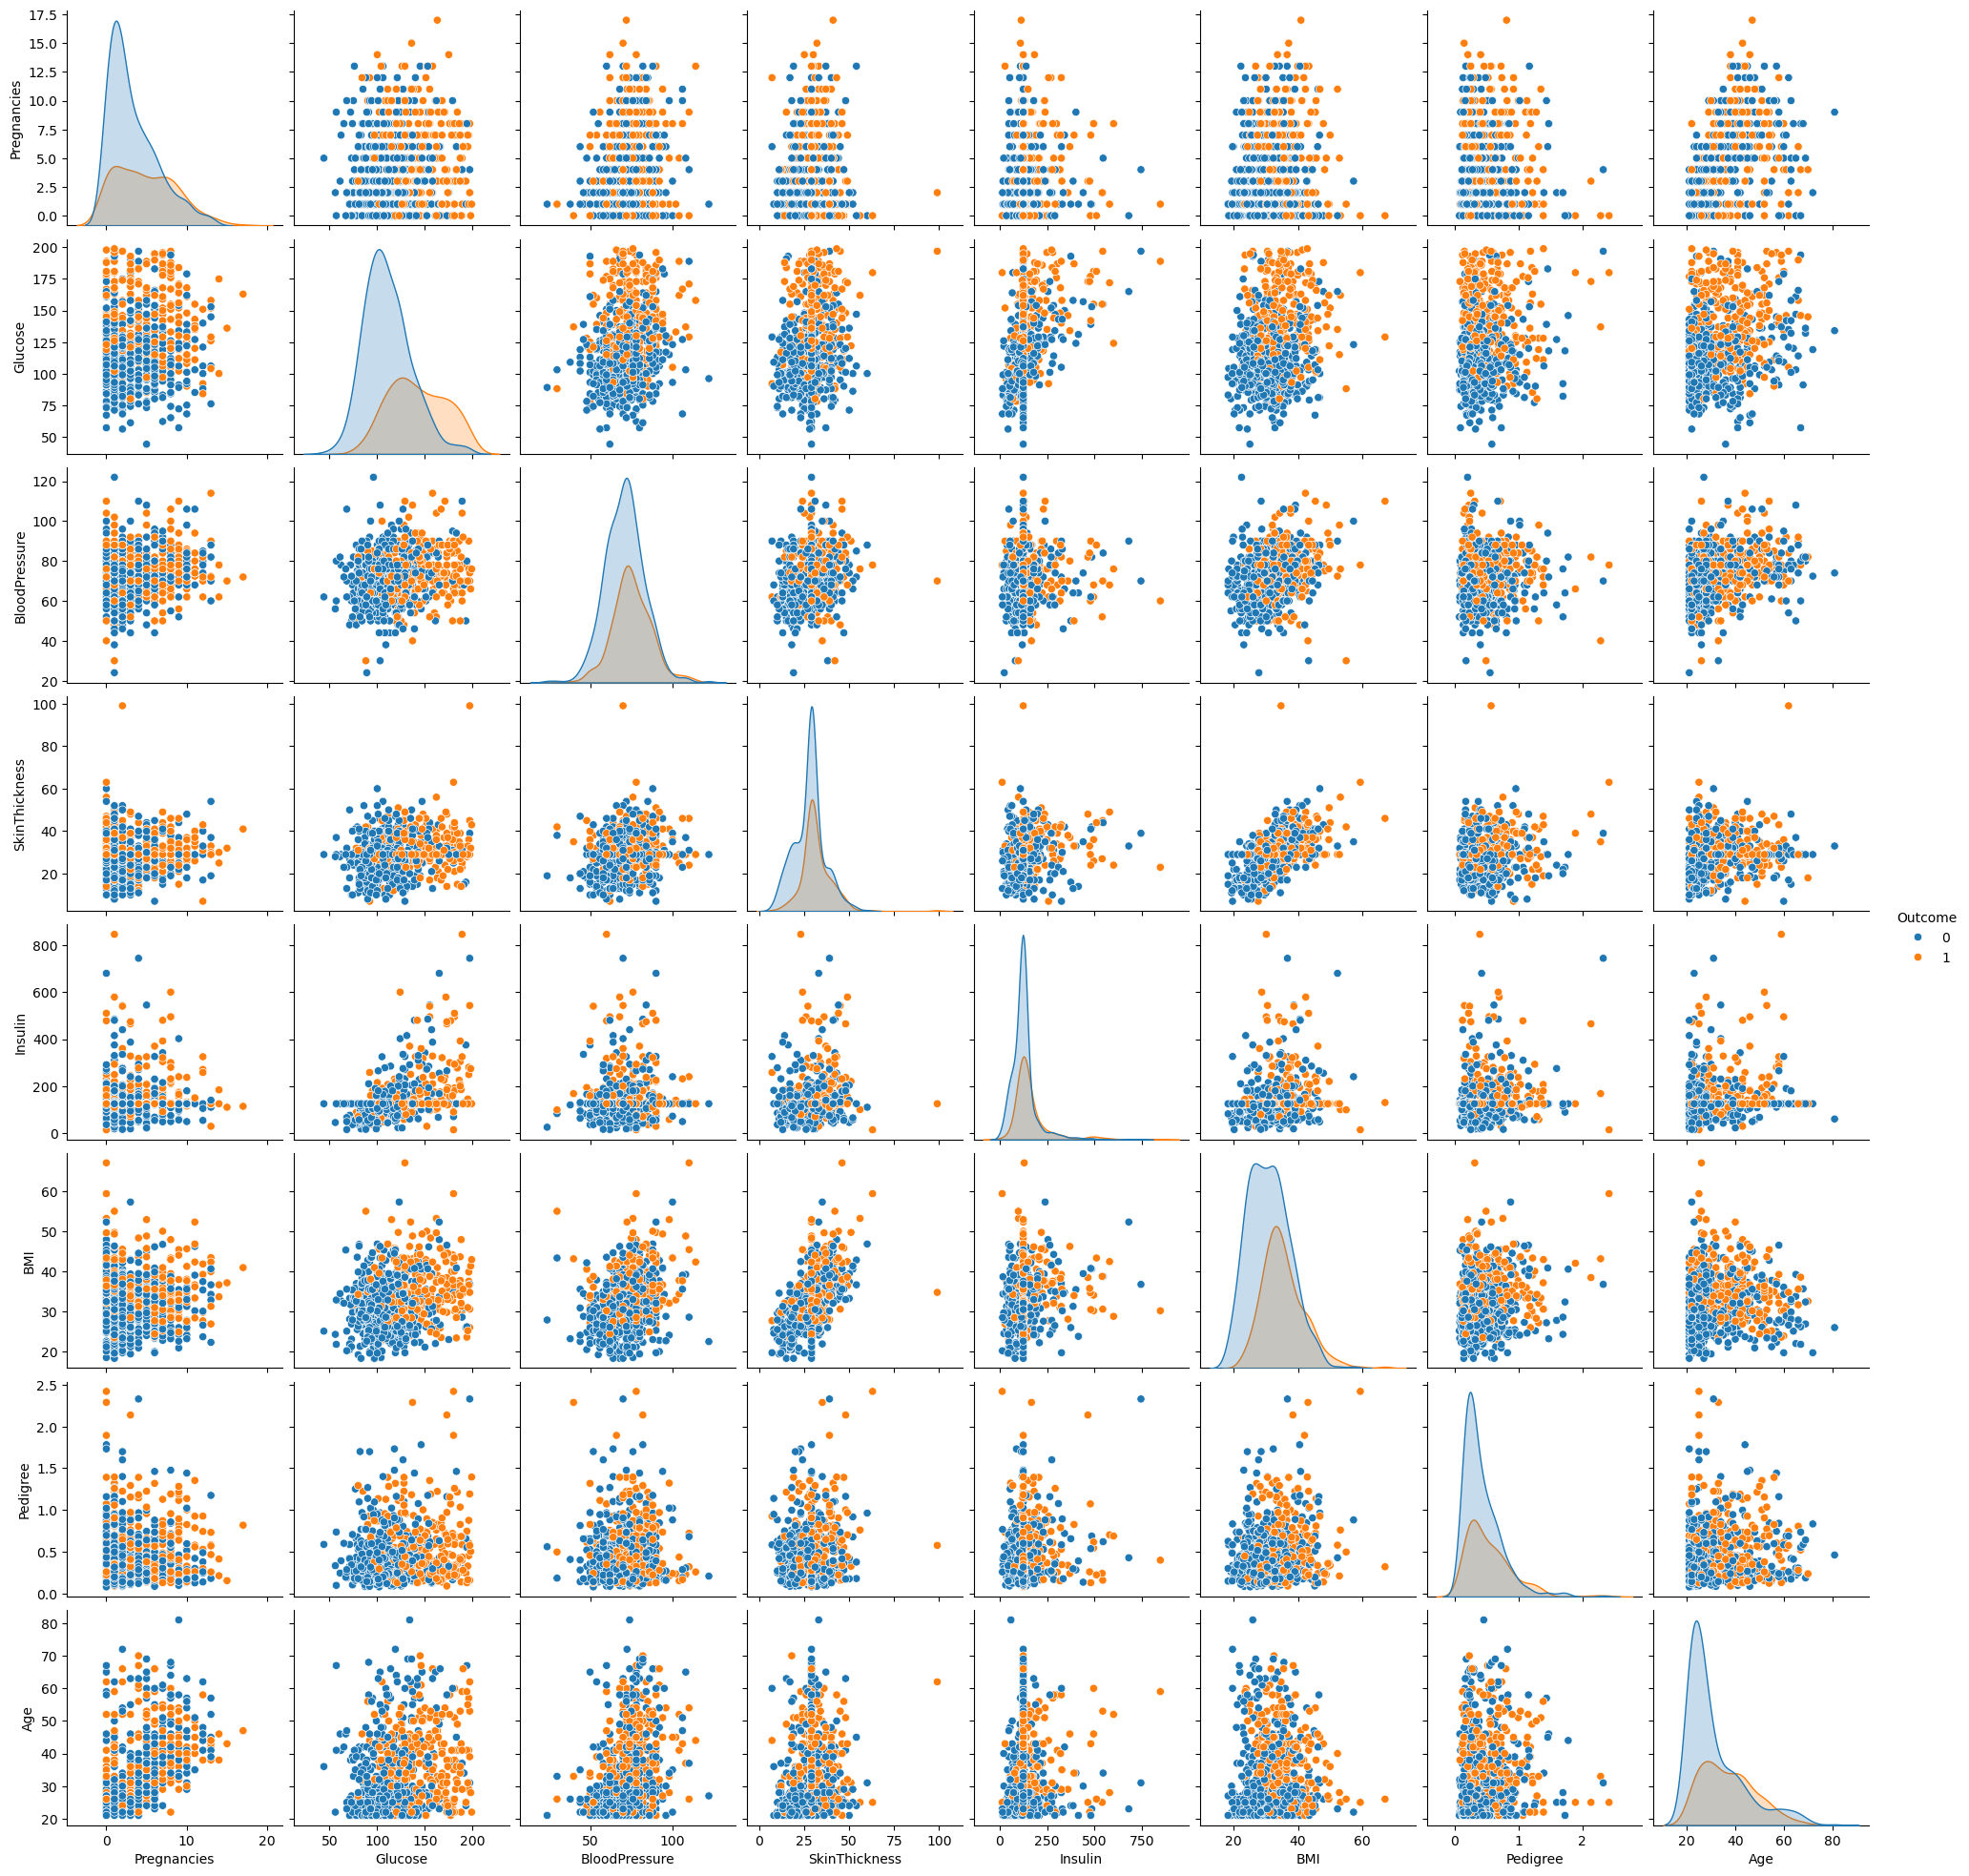

In [19]:
# Step 12: Pair plot
sns.pairplot(diabetes_data_copy, hue='Outcome')
plt.show()

In [20]:
# Step 13: Separate input and output
X = diabetes_data_copy.drop('Outcome', axis=1)
y = diabetes_data_copy['Outcome']

In [21]:
# Step 14: Standardize input features
scaler = StandardScaler()
X = pd.DataFrame(
    scaler.fit_transform(X),
    columns=X.columns
)

In [22]:
# Step 15: Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=1/3,
    random_state=42,
    stratify=y
)

In [23]:
# Step 16: Find best K value
train_scores = []
test_scores = []

for k in range(1, 15):
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train, y_train)

    train_scores.append(knn.score(X_train, y_train))
    test_scores.append(knn.score(X_test, y_test))

print("\nMaximum Training Accuracy:", max(train_scores))
print("Maximum Testing Accuracy:", max(test_scores))


Maximum Training Accuracy: 1.0
Maximum Testing Accuracy: 0.765625


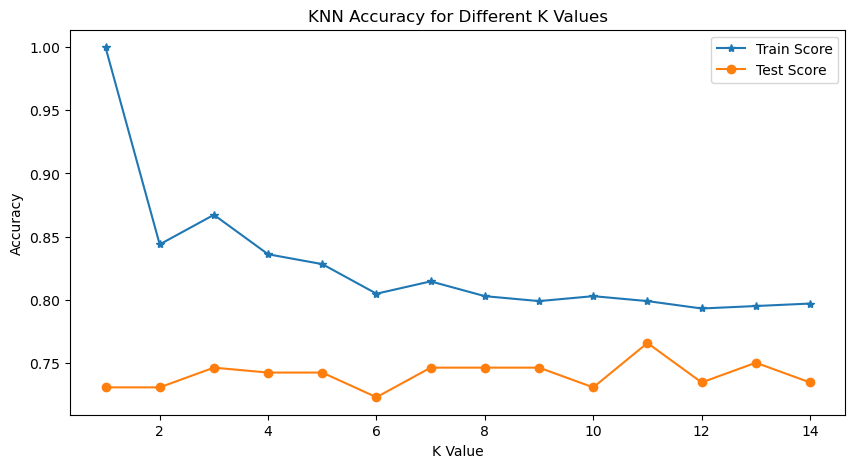

In [24]:
# Step 17: Visualize K values
plt.figure(figsize=(10, 5))
plt.plot(range(1, 15), train_scores, marker='*', label='Train Score')
plt.plot(range(1, 15), test_scores, marker='o', label='Test Score')
plt.xlabel("K Value")
plt.ylabel("Accuracy")
plt.title("KNN Accuracy for Different K Values")
plt.legend()
plt.show()

In [25]:
# Step 18: Train final KNN model
knn = KNeighborsClassifier(n_neighbors=11)
knn.fit(X_train, y_train)

KNeighborsClassifier(n_neighbors=11)

In [26]:
# Step 19: Prediction
y_pred = knn.predict(X_test)

In [27]:
# Step 20: Accuracy
print("\nKNN Accuracy:", knn.score(X_test, y_test))



KNN Accuracy: 0.765625


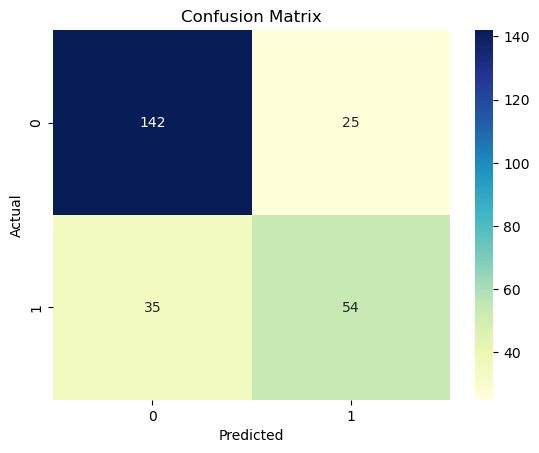

In [28]:
# Step 21: Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm, annot=True, fmt='d', cmap='YlGnBu')
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [29]:
# Step 22: Classification Report
print("\nClassification Report:")
print(classification_report(y_test, y_pred))



Classification Report:
              precision    recall  f1-score   support

           0       0.80      0.85      0.83       167
           1       0.68      0.61      0.64        89

    accuracy                           0.77       256
   macro avg       0.74      0.73      0.73       256
weighted avg       0.76      0.77      0.76       256



In [ ]:




# Step 23: ROC-AUC
y_pred_proba = knn.predict_proba(X_test)[:, 1]

fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)

plt.plot(fpr, tpr, label='KNN')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()

print("ROC-AUC Score:", roc_auc_score(y_test, y_pred_proba))

# Step 24: Hyperparameter tuning
param_grid = {'n_neighbors': np.arange(1, 50)}

knn_model = KNeighborsClassifier()

grid = GridSearchCV(
    knn_model,
    param_grid,
    cv=5
)

grid.fit(X, y)

print("\nBest Score:", grid.best_score_)
print("Best Parameters:", grid.best_params_)
